In [2]:
import pandas as pd

In [3]:
df=pd.read_csv("data/train.csv")

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
df.shape

(891, 12)

In [7]:
df.describe()   

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

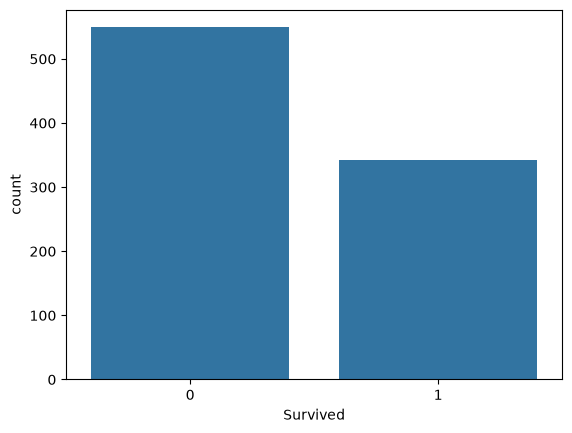

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(
    data=df,
    x="Survived"

)
plt.show()

In [10]:
df.groupby("Sex")["Survived"].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [11]:
df.groupby("Pclass")["Survived"].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [12]:
df.groupby(["Sex", "Pclass"])["Survived"].mean()

Sex     Pclass
female  1         0.968085
        2         0.921053
        3         0.500000
male    1         0.368852
        2         0.157407
        3         0.135447
Name: Survived, dtype: float64

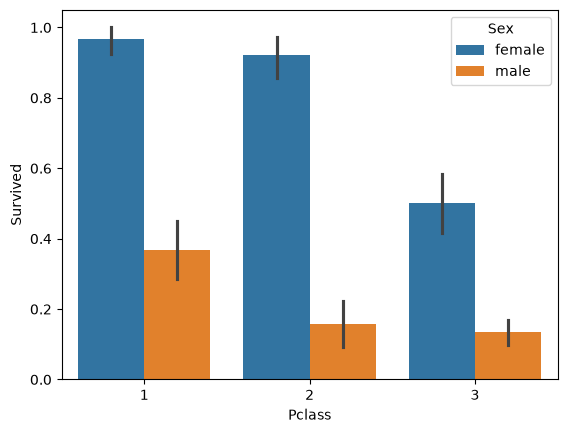

In [13]:
sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Sex"
)
plt.show()

In [14]:
print(df["Age"].isnull().sum())

177


In [15]:
print(df["Cabin"].isnull().sum())

687


In [16]:
print(df["Embarked"].isnull().sum())

2


In [17]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [18]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    "Missing Percentage",
    ascending=False
)

missing

,Missing Count,Missing Percentage
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Name,0,0.000000
Pclass,0,0.000000
Survived,0,0.000000
Sex,0,0.000000
Parch,0,0.000000
SibSp,0,0.000000


In [19]:
df["Cabin"].value_counts()

Cabin
G6             4
C23 C25 C27    4
B96 B98        4
F33            3
E101           3
              ..
E17            1
A24            1
C50            1
B42            1
C148           1
Name: count, Length: 147, dtype: int64

In [20]:
df["Cabin"].nunique()

147

In [21]:
df["Deck"] = df["Cabin"].str[0]

df.groupby("Deck")["Survived"].agg(
    ["count", "mean"]
).sort_values("count", ascending=False)

,count,mean
Deck,,
C,59,0.593220
B,47,0.744681
D,33,0.757576
E,32,0.750000
A,15,0.466667
F,13,0.615385
G,4,0.500000
T,1,0.000000


In [22]:
df["CabinKnown"] = df["Cabin"].notna().astype(int)

df.groupby("CabinKnown")["Survived"].agg(
    ["count", "mean"]
)

,count,mean
CabinKnown,,
0,687,0.299854
1,204,0.666667


In [23]:
df.groupby(["Pclass", "Sex"])["Age"].median()

Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64

In [24]:
df["Embarked"].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

In [25]:
df["Age"].describe()


count    714.000000
mean      29.699118
std       14.526497
min        0.420000
25%       20.125000
50%       28.000000
75%       38.000000
max       80.000000
Name: Age, dtype: float64

In [26]:
df_model = df.copy()


In [27]:
df_model["Deck"] = df_model["Cabin"].str[0]
df_model["CabinKnown"] = df_model["Cabin"].notna().astype(int)


In [28]:
y = df_model["Survived"]

X = df_model[
    [
        "Pclass", "Sex", "Age", "SibSp", "Parch",
        "Fare", "Embarked", "Deck", "CabinKnown"
    ]
]


In [29]:
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing values:")
print(X.isnull().sum())

Feature shape: (891, 9)
Target shape: (891,)
Missing values:
Pclass          0
Sex             0
Age           177
SibSp           0
Parch           0
Fare            0
Embarked        2
Deck          687
CabinKnown      0
dtype: int64


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (712, 9)
X_test: (179, 9)


In [36]:
from sklearn.impute import SimpleImputer
age_imputer=SimpleImputer(strategy="median")
X_train[["Age"]]=age_imputer.fit_transform(X_train[["Age"]])

In [37]:
X_test[["Age"]]=age_imputer.transform(X_test[["Age"]])

In [38]:
X_train.isnull().sum()

Pclass          0
Sex             0
Age             0
SibSp           0
Parch           0
Fare            0
Embarked        2
Deck          552
CabinKnown      0
dtype: int64

In [39]:
X_train["Embarked"]

692    S
481    S
527    S
855    S
801    S
      ..
359    Q
258    C
736    S
462    S
507    S
Name: Embarked, Length: 712, dtype: str

In [42]:
embarked_mode=X_train["Embarked"].mode()[0]
X_train["Embarked"]=X_train["Embarked"].fillna(embarked_mode)
X_test["Embarked"]=X_test["Embarked"].fillna(embarked_mode)

In [43]:
X_train.isnull().sum()

Pclass          0
Sex             0
Age             0
SibSp           0
Parch           0
Fare            0
Embarked        0
Deck          552
CabinKnown      0
dtype: int64

In [44]:
X_train["Deck"]=X_train["Deck"].fillna("missing")
X_test["Deck"]=X_test["Deck"].fillna("missing")

In [45]:
X_train.isnull().sum()


Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
Deck          0
CabinKnown    0
dtype: int64

In [46]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      712 non-null    int64  
 1   Sex         712 non-null    str    
 2   Age         712 non-null    float64
 3   SibSp       712 non-null    int64  
 4   Parch       712 non-null    int64  
 5   Fare        712 non-null    float64
 6   Embarked    712 non-null    str    
 7   Deck        712 non-null    str    
 8   CabinKnown  712 non-null    int64  
dtypes: float64(2), int64(4), str(3)
memory usage: 55.6 KB


In [47]:
categories=["Sex","Embarked","Deck"]
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


In [48]:
X_train_encoded=encoder.fit_transform(X_train[categories])
X_test_encoded=encoder.transform(X_test[categories])

In [50]:
X_train_encoded

array([[0., 1., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 1.]], shape=(712, 14))

In [51]:
print("Training encoded shape:", X_train_encoded.shape)
print("Testing encoded shape:", X_test_encoded.shape)
print("Categories learned:", encoder.categories_)

Training encoded shape: (712, 14)
Testing encoded shape: (179, 14)
Categories learned: [array(['female', 'male'], dtype=object), array(['C', 'Q', 'S'], dtype=object), array(['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T', 'missing'], dtype=object)]


In [52]:
import numpy as np

numeric_cols = [
    "Pclass", "Age", "SibSp", "Parch", "Fare", "CabinKnown"
]

X_train_final = np.concatenate(
    [
        X_train[numeric_cols].to_numpy(),
        X_train_encoded
    ],
    axis=1
)

X_test_final = np.concatenate(
    [
        X_test[numeric_cols].to_numpy(),
        X_test_encoded
    ],
    axis=1
)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (712, 20)
Final testing shape: (179, 20)


In [54]:
X_train_final

array([[ 3. , 28.5,  0. , ...,  0. ,  0. ,  1. ],
       [ 2. , 28.5,  0. , ...,  0. ,  0. ,  1. ],
       [ 1. , 28.5,  0. , ...,  0. ,  0. ,  0. ],
       ...,
       [ 3. , 48. ,  1. , ...,  0. ,  0. ,  1. ],
       [ 1. , 47. ,  0. , ...,  0. ,  0. ,  0. ],
       [ 1. , 28.5,  0. , ...,  0. ,  0. ,  1. ]], shape=(712, 20))

In [56]:
import pandas as pd

categorical_cols = ["Sex", "Embarked", "Deck"]
numeric_cols = [
    "Pclass", "Age", "SibSp", "Parch", "Fare", "CabinKnown"
]

# Get names for the new encoded columns
encoded_cols = encoder.get_feature_names_out(categorical_cols)

# Convert encoded arrays to DataFrames
X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=encoded_cols,
    index=X_train.index
)

X_test_encoded_df = pd.DataFrame(
    X_test_encoded,
    columns=encoded_cols,
    index=X_test.index
)

In [57]:
# Keep numerical columns and add encoded categorical columns
X_train = pd.concat(
    [X_train[numeric_cols], X_train_encoded_df],
    axis=1
)

X_test = pd.concat(
    [X_test[numeric_cols], X_test_encoded_df],
    axis=1
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print(X_train.head())

Training shape: (712, 20)
Testing shape: (179, 20)
     Pclass   Age  SibSp  Parch      Fare  CabinKnown  Sex_female  Sex_male  \
692       3  28.5      0      0   56.4958           0         0.0       1.0   
481       2  28.5      0      0    0.0000           0         0.0       1.0   
527       1  28.5      0      0  221.7792           1         0.0       1.0   
855       3  18.0      0      1    9.3500           0         1.0       0.0   
801       2  31.0      1      1   26.2500           0         1.0       0.0   

     Embarked_C  Embarked_Q  Embarked_S  Deck_A  Deck_B  Deck_C  Deck_D  \
692         0.0         0.0         1.0     0.0     0.0     0.0     0.0   
481         0.0         0.0         1.0     0.0     0.0     0.0     0.0   
527         0.0         0.0         1.0     0.0     0.0     1.0     0.0   
855         0.0         0.0         1.0     0.0     0.0     0.0     0.0   
801         0.0         0.0         1.0     0.0     0.0     0.0     0.0   

     Deck_E  Deck_F  De

In [58]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [60]:
from sklearn.metrics import accuracy_score
acc=accuracy_score(y_test,y_pred)
print(acc*100)

81.56424581005587


In [61]:


print("Predictions:", y_pred[:10])
print("Actual values:", y_test.iloc[:10].tolist())

Predictions: [0 0 0 0 1 0 1 0 0 0]
Actual values: [0, 0, 1, 0, 1, 1, 1, 0, 0, 0]


In [62]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.8156424581005587
Accuracy percentage: 81.56 %


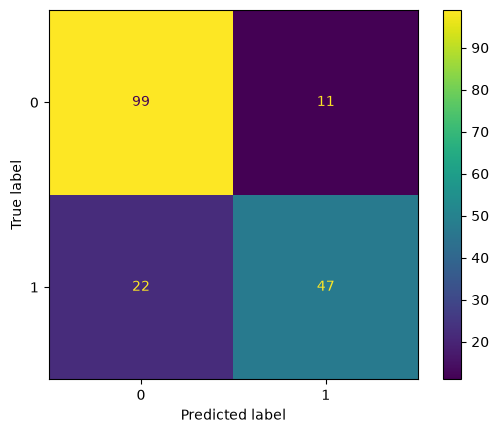

In [64]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm=confusion_matrix(y_test,y_pred)
disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,

)
disp.plot()
plt.show()

In [65]:
from sklearn.metrics import classification_report
cf=classification_report(y_test,y_pred)
print(cf)

              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.68      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179



In [66]:
from sklearn.tree import DecisionTreeClassifier
model_dt=DecisionTreeClassifier(max_depth=5,random_state=42)
model_dt.fit(X_train,y_train)
y_pred=model_dt.predict(X_test)

In [67]:
accuracy_dt=accuracy_score(y_test,y_pred)

In [68]:
print(accuracy_dt)

0.770949720670391


In [69]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



In [70]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

print(classification_report(y_test, dt_pred))


Decision Tree Accuracy: 77.09 %
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



In [71]:

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

print(classification_report(y_test, rf_pred))


Random Forest Accuracy: 79.89 %
              precision    recall  f1-score   support

           0       0.80      0.89      0.84       110
           1       0.79      0.65      0.71        69

    accuracy                           0.80       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179



In [72]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": (model, model.predict(X_test)),
    "Decision Tree": (dt_model, dt_pred),
    "Random Forest": (rf_model, rf_pred)
}

results = []

for name, (trained_model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, predictions), 3),
        "Precision": round(precision_score(y_test, predictions), 3),
        "Recall": round(recall_score(y_test, predictions), 3),
        "F1-score": round(f1_score(y_test, predictions), 3)
    })

comparison = pd.DataFrame(results)
comparison


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.816,0.810,0.681,0.740
1,Decision Tree,0.771,0.719,0.667,0.692
2,Random Forest,0.799,0.789,0.652,0.714


In [73]:

from sklearn.model_selection import train_test_split

numeric_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = ["Sex", "Embarked"]

X = df[numeric_features + categorical_features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
